# 광고 증분 효과 측정 보고서
## Conversion Lift Study: 상품 광고 vs 공익광고 홀드아웃

| 항목 | 내용 |
|---|---|
| 목적 | 온라인 광고 캠페인이 상품 구매를 **얼마나 추가로 만들어냈는지(증분 효과)** 측정하고 예산 의사결정 기준 제시 |
| 데이터 | Kaggle *Marketing A/B Testing*, 사용자 588,101명 |
| 설계 | 사용자 단위 무작위 홀드아웃 실험 (노출군 96% : 홀드아웃 4%) |
| 핵심 지표 | 구매 전환율 (`converted`) |
| 분석 기준일 | 2026-11-06 |

**보고서 구성**

| 파트 | 내용 |
|---|---|
| Part 0 | Executive Summary: 결과와 권고 한 장 요약 |
| Part 1 | 탐색적 데이터 분석(EDA): 실험 배경·가설(E0) → 데이터 점검과 탐색(E1~E6) → 검정력·손익분기 프레임(E7) → 종합 점검표(E8) |
| Part 2 | 본 분석: 가이드라인 6단계에 따른 검정과 의사결정 |
| 부록 | 용어 정리, EDA 그림 재생성 코드 |

# Part 0. Executive Summary

> 분석을 모두 마친 뒤 작성한 요약을 맨 앞에 배치했다. 가설과 검정 방법은 결과를 보기 전에 확정했다(Part 1 E0).

### 측정 질문
**미공개 상품의 온라인 광고는, 같은 자리에 공익광고를 보여준 홀드아웃 대비 그 상품의 구매 전환율을 높였는가?**

### 핵심 결과

| KPI | 노출군 (광고) | 홀드아웃 (공익광고) | 증분 효과 |
|---|---|---|---|
| 사용자 수 | 564,577 | 23,524 | |
| 구매 전환율 | **2.555%** | **1.785%** | **+0.77%p** (95% CI +0.59 ~ +0.94) |
| Lift (상대 증가) | | | **+43%** (1.43배, 95% CI 1.30 ~ 1.58) |
| 증분 구매 수 | | | **약 4,300건** (95% CI 약 3,300 ~ 5,300) |
| 통계적 유의성 | | | χ²(1) = 54.3, p < .001 |

- **광고를 본 1,000명 중 약 8명이 광고 덕분에 추가로 구매했다.** 증분 구매 1건을 만들려면 노출군 사용자 약 130명이 필요하다.
- 노출 요일·시간을 통제해도(오즈비 1.44), 노출이 극단적으로 많은 상위 1%를 제외해도(+0.79%p) 결론이 같다.
- 이 실험이 검출할 수 있는 최소 효과(MDE)는 약 0.26%p로, 관측된 증분 효과는 그 약 3배다. **측정력이 충분한 실험**이었다.

### 권고

| 구분 | 권고 | 요지 |
|---|---|---|
| ✅ **Go** | 캠페인 유지 | 광고의 증분 효과가 통계적으로 확실하고 실무적으로도 의미 있는 크기 |
| ⚠️ **Conditional** | 예산 확대는 손익분기 확인 후 | 구매 1건 공헌이익이 1인당 광고비의 **약 130배 이상**이어야 이익. 예: 공헌이익 3만 원이면 손익분기 CPM 약 9,300원, 보수적 기준 약 7,100원. 실제 CPM이 보수적 기준보다 낮으면 확대 (계산 과정: E7) |
| ⏸ **Hold** | 요일·시간 타겟팅 보류 | 사후 탐색으로 찾은 패턴, 다중비교 보정 후 근거 약함 → 별도 실험 필요 |
| ⏸ **Hold** | 노출 빈도 상향 보류 | 노출 수는 처치 이후 변수라 인과 근거 없음 → 빈도 실험 필요 |

### 다음 단계
① 상품 마진·광고비 데이터를 연결해 **iROAS**와 **증분 전환 1건당 비용**을 정식 KPI로 산출 ② 요일 타겟팅·노출 빈도를 **사전 등록한 후속 실험**으로 검증

---

# Part 1. 탐색적 데이터 분석 (EDA)

> 본 분석에 앞서 데이터를 **가이드라인의 각 단계가 요구하는 관점**으로 점검했다. 순서는 E0(실험 배경·구성·가설) → E1~E6(데이터 점검과 탐색) → E7(검정력·손익분기 프레임) → E8(종합 점검표)이며, 각 섹션 끝의 **→ 본 분석 반영**은 해당 관찰이 Part 2의 어느 단계에 쓰이는지를 뜻한다.

## E0. 실험 배경, 구성과 가설

### 실험 배경: 무슨 상황인가

어떤 회사가 **자사 상품의 온라인 광고 캠페인**을 집행했다. 상품 이름·가격, 회사, 나라, 플랫폼, 기간은 **공개돼 있지 않다.** 회사가 알고 싶었던 것은 단순히 "광고를 본 사람이 얼마나 샀나"가 아니라, **"광고가 없었어도 살 사람을 빼고, 광고 덕분에 새로 생긴 구매가 얼마나 되나"** 였다.

그래서 광고 자리에 노출되는 사용자 중 **96%에게는 상품 광고**를, **무작위로 고른 4%에게는 같은 자리에 상품과 무관한 공익광고(PSA)** 를 보여줬다. 공익광고를 본 사람도 상품을 살 수는 있다. 광고를 못 봤을 뿐, 원래 관심이 있었거나 검색·추천 등 다른 경로로 살 수 있기 때문이다. 이후 두 집단에서 **그 상품을 구매했는지(`converted`)** 를 기록했다.

> **연구 질문**: 어떤 (이름 모를) 상품의 온라인 광고가, 같은 자리에 공익광고를 보여줬을 때에 비해 그 상품의 구매율을 높였나?

```
광고 자리에 노출되는 사용자 588,101명
        │
        ├─ 무작위 96% ──▶ 상품 광고를 봄 ────▶ 그 상품을 샀나? (converted)
        │
        └─ 무작위  4% ──▶ 공익광고를 봄 ────▶ 그 상품을 샀나? (converted)
                         (자리·노출 횟수는 같고, 상품 홍보만 빠짐)
```

**두 집단을 비교하면 무엇이 보이나**

| 집단 | 구매율이 뜻하는 것 |
|---|---|
| 홀드아웃 | 광고 없이도 **원래 살 사람**의 비율 (기준선) |
| 노출군 | 원래 살 사람 **+ 광고 때문에 산 사람** |
| 차이 (광고 − 공익광고) | **광고가 새로 만들어낸 구매** = 광고의 증분(incremental) 효과 |

홀드아웃 없이 노출군의 구매율만 보면, 원래 살 사람까지 광고 덕분으로 쳐서 효과를 크게 부풀리게 된다. 빈칸 대신 공익광고를 넣은 이유는 화면 배치와 노출 횟수는 그대로 두고 **상품 홍보만 빼기 위해서**다. 그래야 차이를 순수하게 광고 내용의 효과로 볼 수 있다.

> 이 데이터로 말할 수 있는 범위: "**미공개 상품**의 광고가 구매율을 얼마나 높였나"까지다. 상품 가격이나 매출 정보가 없어 광고의 금전적 가치는 계산할 수 없고, 다른 상품·시장에 그대로 일반화할 수도 없다.

### 실험 구성 요약

| 구성요소 | 이 실험에서 | 비고 |
|---|---|---|
| 상황 | 미공개 상품의 온라인 광고 캠페인 | 상품·회사·기간 미공개 |
| 알고 싶은 것 | 광고가 그 상품의 구매율을 높였나 | 광고의 **증분 효과** |
| 전환(`converted`)의 뜻 | 그 상품을 **구매**했는지 (0/1) | 매출액은 없음 |
| A (통제집단) | **공익광고(psa)** 를 본 사용자 23,524명 | 광고 자리는 같고 내용만 다름 |
| B (처치집단) | **실제 광고(ad)** 를 본 사용자 564,577명 | |
| 무작위 배정 단위 | 사용자 1명 | 96:4 홀드아웃 배정으로 추정 |
| 독립변수 (IV) | `test_group` (ad / psa) | |
| 종속변수 (DV) | `converted` 구매 여부 (0/1) | 비율 지표 |
| 효과 | $\Delta = p_{ad} - p_{psa}$ | 절대 %p와 상대 배수로 보고 |
| 세그먼트·보조 변수 | `total_ads`, `most_ads_day`, `most_ads_hour` | 모두 실험 중 정해진 값 |

### 가설

> ⚠️ 아래 가설·유의수준·양측 여부는 **E3(결과 지표 탐색) 이전에** 정했다. EDA에서 집단별 전환율을 본 뒤 가설을 바꾸면 p-해킹이 되므로 이후 단계에서 바꾸지 않는다.

**귀무가설 $H_0$**: 광고는 전환에 영향이 없다. 노출군과 홀드아웃의 전환율이 같다.

$$H_0:\; p_{ad} = p_{psa} \quad (\Delta = 0)$$

**대립가설 $H_1$**: 광고는 전환율을 바꾼다. 두 집단의 전환율이 다르다.

$$H_1:\; p_{ad} \neq p_{psa} \quad (\Delta \neq 0)$$

| 설정 | 값 | 이유 |
|---|---|---|
| 유의수준 | $\alpha = 0.05$ | 관례적 기준 |
| 방향 | **양측** | 광고가 거부감을 줘 전환을 오히려 낮출 가능성도 배제하지 않음 |
| 검정통계량 | 두 비율 z (= 카이제곱, $\chi^2 = z^2$) | 비율 지표 · 독립 두 집단 |

$$z = \frac{\hat{p}_{ad} - \hat{p}_{psa}}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_{ad}} + \frac{1}{n_{psa}}\right)}} \qquad (\hat{p} = H_0\text{ 아래 두 집단을 합친 전환율})$$

**판정 규칙**: $p < 0.05$이면 $H_0$를 기각하고 "광고 효과가 있다"고 결론 낸다. $p \geq 0.05$이면 $H_0$를 기각하지 못하며, 이는 "효과가 없다"가 아니라 "효과가 있다는 증거가 부족하다"로 읽는다.

| 판정 오류 | 뜻 | 이 실험에서의 대가 |
|---|---|---|
| **1종 오류** (확률 $\alpha$) | 효과가 없는데 있다고 함 | 효과 없는 광고에 계속 광고비 지출 |
| **2종 오류** (확률 $\beta$) | 효과가 있는데 놓침 | 효과 있는 캠페인을 중단 |

## E1. 데이터 개요: 구조·자료형·결측·범위

| 컬럼 | 자료형 | 고유값 수 | 결측 | 범위 / 값 | 역할 |
|---|---|---|---|---|---|
| `user_id` | 정수 | 588,101 | 0 | 900,000~1,654,483 | 식별자 (행마다 고유) |
| `test_group` | 문자 | 2 | 0 | `ad`, `psa` | **IV** (무작위 배정) |
| `converted` | 정수 0/1 | 2 | 0 | 평균 0.025 | **DV** |
| `total_ads` | 정수 | 807 | 0 | 1~2,065 (중앙값 13, 평균 24.8) | 노출량 — **처치 이후 변수** |
| `most_ads_day` | 문자 | 7 | 0 | Monday~Sunday | 세그먼트 — 실험 중 행동 |
| `most_ads_hour` | 정수 | 24 | 0 | 0~23 | 세그먼트 — 실험 중 행동 |

- 원본 캐글 파일 대비 차이: 행 번호 컬럼 삭제, 컬럼명 공백 → `_`, `converted` True/False → 1/0 (체크섬으로 동일 파일 확인).
- `total_ads`에 0이 없다(최솟값 1). 모든 사용자가 광고 자리에 최소 1번은 노출됐다는 뜻으로, 실험 대상 정의와 일치한다.
- **사전 특성(나이, 기존 구매 이력 등)이 하나도 없다.** 그래서 무작위 배정 품질은 처치 이후 변수로 간접적으로만 확인할 수 있다(E4).

**→ 본 분석 반영**: 자료형 변환 불필요. 사전 공변량이 없으므로 회귀 통제는 강건성 확인용으로만 사용.

## E2. 데이터 위생 점검: 중복·배정 일관성·SRM

| 점검 | 결과 | 판단 |
|---|---|---|
| `user_id` 중복 | 0행 | 정상 |
| 완전히 같은 행 | 0행 | 정상 |
| 한 사용자가 `ad`와 `psa`에 동시 배정 | 0명 | 정상 (배정 라벨 어긋남 없음) |
| `test_group` 값 | `ad`, `psa`만 존재 | 정상 |
| `converted` 값 | 0, 1만 존재 | 정상 |
| **SRM — 50:50 기준** | p ≈ 0 | ❌ **잘못된 기준**: 이 실험은 처음부터 50:50이 아님 |
| **SRM — 96:4 기준** | χ² ≈ 0.00, p ≈ 1.00 | ✅ 관측 96.0000 : 4.0000이 추정 의도 비율과 일치 |

- SRM은 **의도한 비율**과 비교해야 한다. 광고 집행이 목적이라 소수만 통제집단으로 남긴 '홀드아웃' 설계로 보이며, 관측 비율이 소수점 넷째 자리까지 96:4로 딱 떨어져 의도 비율로 추정했다. 다만 **이 비율이 문서로 확인되지 않았다**는 점은 한계로 남긴다.
- 홀드아웃이 4%뿐이라 **효과 추정의 정밀도는 작은 쪽 집단 크기(23,524명)에 묶인다.** 오른쪽 그림에서 공익광고 신뢰구간이 훨씬 긴 이유다.

**정제 메모**: 정제 전 588,101행 → 정제 후 588,101행. 문제 행이 없어 **아무것도 제거하지 않았다.**

**→ 본 분석 반영**: 1단계 SRM은 96:4 기준으로 수행, 50:50 결과는 '잘못된 기준' 예시로만 제시.

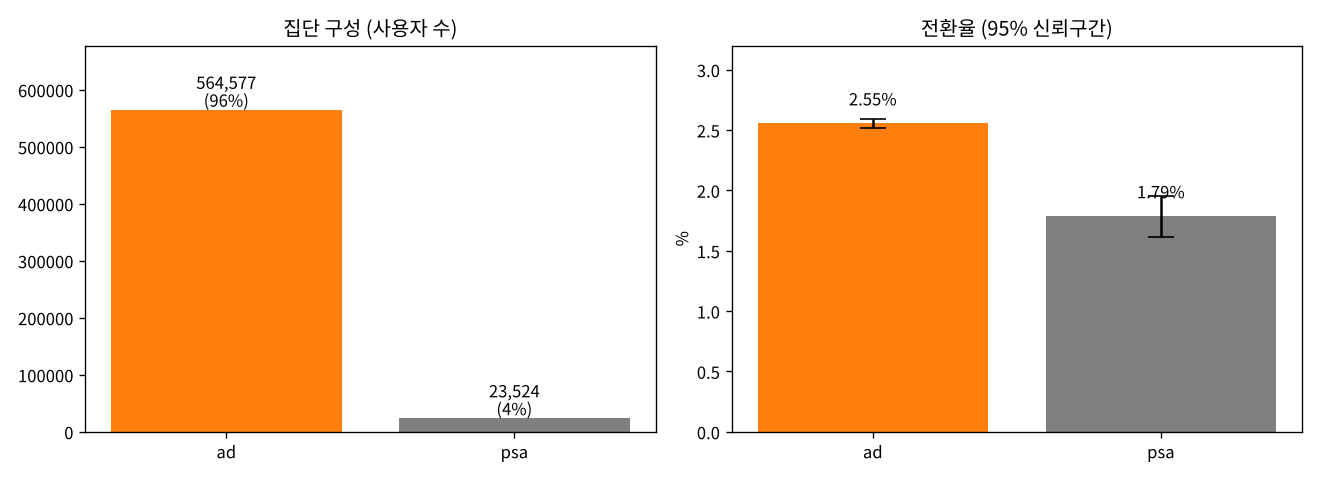

## E3. 결과 지표(DV) 탐색: 검정 선택을 위한 확인

| 항목 | 광고 (ad) | 공익광고 (psa) |
|---|---|---|
| 사용자 수 | 564,577 | 23,524 |
| 전환 수 | 14,423 | 420 |
| 전환율 | 2.555% | 1.785% |
| 표준오차 | 0.021%p | 0.086%p |
| 2×2 표 최소 기대빈도 | | 약 594 |

**검정 선택에 주는 정보 (3단계 세 질문)**

1. 지표는 **비율** (0/1) → 평균·분산이 아니라 비율 비교
2. 집단은 **2개, 서로 다른 사용자(독립)** → 대응 검정 아님
3. 비율 지표라 **정규성·등분산 점검은 해당 없음**. 대신 카이제곱 근사 조건(모든 칸 기대빈도 ≥ 5)을 확인 → 최소 약 594로 충분

전환은 **2.5% 안팎의 희귀 사건**이다. 이런 지표에서는 Cramér's V 같은 효과크기가 구조적으로 작게 나오므로, 4단계에서 **절대 차이(%p)와 상대 차이(배)를 반드시 함께** 보고해야 한다.

**pdf 그림 읽기**

- **왼쪽**: 집단별 전환율 추정치의 표본분포. 광고는 표본이 커서 뾰족하고, 공익광고는 넓게 퍼져 있다.
- **오른쪽**: **회색 점선** = $H_0$(차이 0)가 맞을 때 차이의 분포, **빨간 영역** = 양측 5% 기각역(±0.20%p 바깥), **파란 곡선** = 관측 차이 +0.77%p의 추정 분포. 관측값이 $H_0$ 중심에서 표준오차 7.4개만큼 떨어져 있다(z = 7.4).

**→ 본 분석 반영**: 3단계에서 카이제곱 독립성 검정(= 두 비율 z검정) 선택, 4단계에서 %p·배수·V·h를 함께 보고.

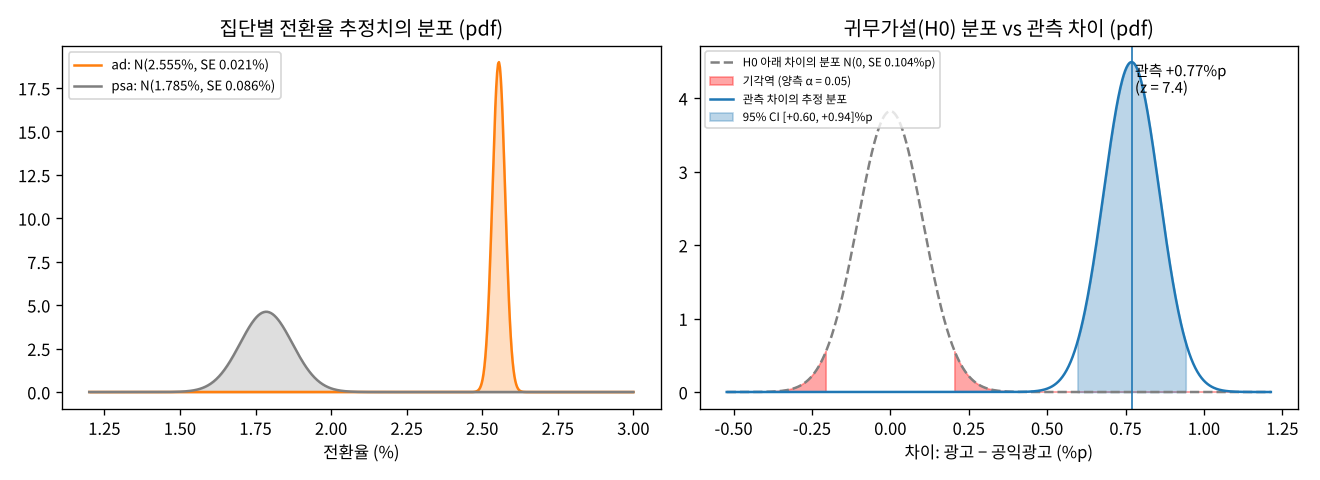

## E4. 무작위 배정 품질: 두 집단은 처음부터 비슷한가

무작위 배정이 제대로 됐다면 결과 지표 외의 변수는 두 집단에서 비슷해야 한다. 이 데이터엔 사전 특성이 없어서 **실험 중 노출 관련 변수**로 간접 점검한다.

| 변수 | 비교 방법 | 결과 | 판단 |
|---|---|---|---|
| `total_ads` (원 척도) | 표준화 평균차 (SMD) | **0.001** | ✅ 균형 (기준: \|SMD\| < 0.1) |
| `total_ads` (로그 척도) | SMD | **0.042** | ✅ 균형 |
| `total_ads` 분포 | 중앙값 / 평균 | 13 vs 12회 / 24.8 vs 24.8회 | ✅ 거의 동일 |
| `most_ads_day` | 카이제곱, Cramér's V | χ²(6) = 235.6, p < .001, **V = 0.020** | ⚠️ 유의하지만 아주 작음 |
| `most_ads_hour` | 카이제곱, Cramér's V | χ²(23) = 192.3, p < .001, **V = 0.018** | ⚠️ 유의하지만 아주 작음 |

- 노출량은 두 집단이 사실상 같다. 광고와 공익광고가 **같은 광고 자리에 같은 빈도로** 노출됐다는 뜻이라 설계가 의도대로 작동한 것으로 보인다.
- 요일·시간 분포 차이는 58만 명 규모라 아주 작은 차이도 유의하게 잡힌 것이다(V ≈ 0.02). 또 이 변수들은 **처치 이후 값**이라, 무작위 배정 실패라기보다 두 광고의 **송출 일정이 조금 달랐던 흔적**에 가깝다. 공익광고 쪽이 목요일과 정오 무렵에 약간 더 몰려 있다(E6 그림).

**→ 본 분석 반영**: 1단계에 보조 점검으로 포함, 4단계에서 요일·시간을 통제한 로지스틱 회귀로 결론이 바뀌지 않는지 확인.

## E5. 분포와 이상치: 노출 수(`total_ads`)

| 통계량 | 값 |
|---|---|
| 중앙값 / 평균 / 표준편차 | 13 / 24.8 / 43.7회 |
| 왜도 | **7.4** (오른쪽 꼬리가 매우 긴 분포) |
| 99백분위수 | 202회 |
| 202회 초과 (상위 1%) | **5,810명** (광고 5,560 / 공익광고 250) |
| 1,000회 초과 | 36명 (최대 2,065회) |

- **왼쪽 위 (pdf)**: 대부분 10~30회 노출. 로그 척도에서 두 집단 곡선이 거의 포개진다. 낮은 구간의 물결은 노출 수가 정수라서 생긴 모양이다.
- **오른쪽 위 (구간별 전환율)**: 전환율은 노출이 많을수록 0.3%에서 15% 이상으로 급증한다. 광고와 공익광고의 차이는 **21~200회 구간에서만** 크게 벌어지고, 20회 이하에서는 거의 없다.
- **아래 오른쪽 (누적분포)**: 상위 1% 경계(202회) 너머로 소수의 극단 사용자가 길게 이어진다.

**이상치를 지워야 하나?** 2,065회 같은 값은 입력 오류라기보다 **실제로 매우 활발한 헤비 유저**일 가능성이 크고, 이들의 전환율은 약 16%로 오히려 높다. 무조건 지우는 대신 **지운 전후를 비교**했다.

| | 광고 전환율 | 공익광고 전환율 | 차이 |
|---|---|---|---|
| 전체 | 2.555% | 1.785% | +0.77%p |
| 상위 1% 제외 | 2.42% | 1.63% | +0.79%p |

→ 결론이 바뀌지 않으므로 **모두 유지**한다.

⚠️ 노출 수 구간별 그림을 "광고를 많이 보여줄수록 효과가 크다"로 읽으면 안 된다. 노출 수는 실험 중에 정해진 값이라 원래 활동량이 많은 사용자일수록 많이 보고 많이 전환했을 수 있다(**처치 이후 변수**). 탐색적 관찰로만 남긴다.

**→ 본 분석 반영**: 이상치 제거 없음, `total_ads`는 통제변수로 쓰지 않고 6단계 한계에 명시.

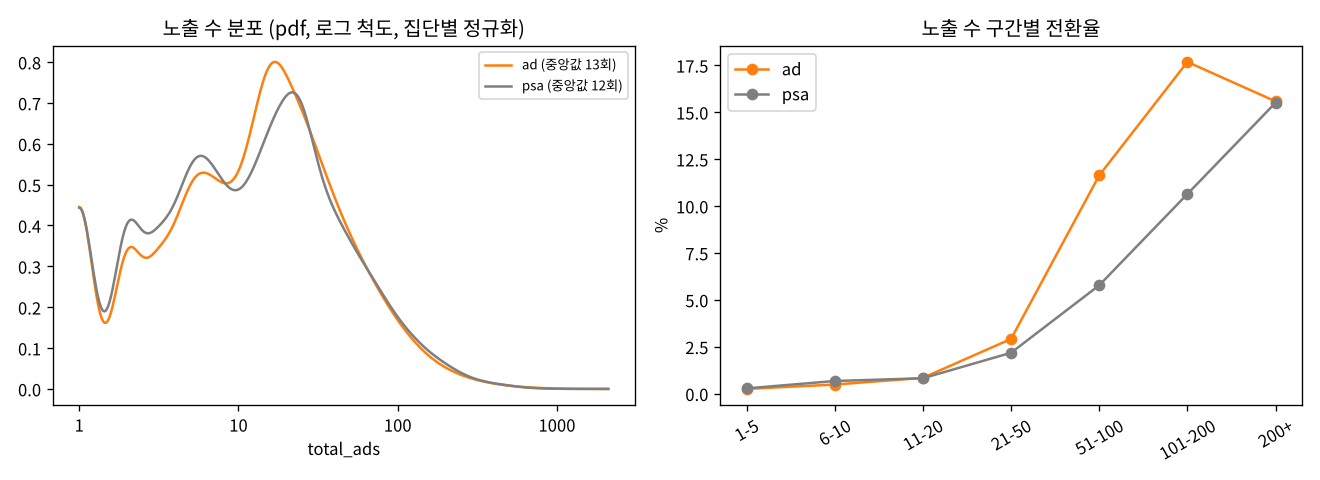

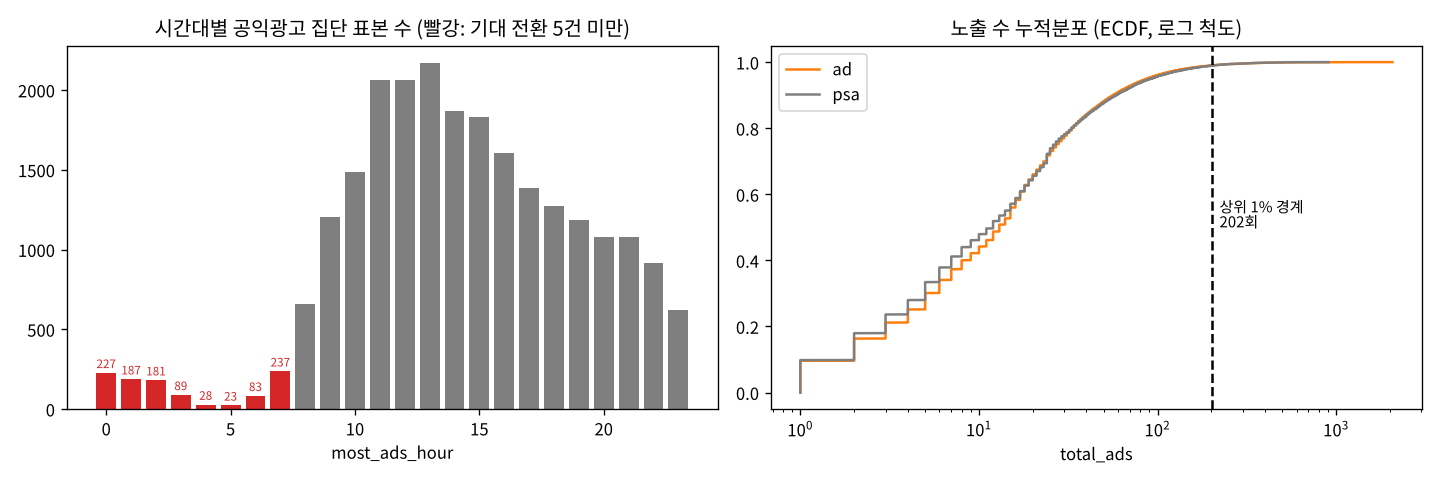

## E6. 세그먼트 탐색: 요일·시간대 (5단계 C 준비)

- **노출 분포 (왼쪽)**: 두 집단의 요일·시간 분포 모양은 대체로 비슷하다(E4의 V ≈ 0.02).
- **전환율 (오른쪽)**: 요일·시간대와 상관없이 **광고 쪽이 거의 항상 높다.** 시간대별로는 오후~저녁(14~21시)이 높고 새벽이 낮다. 요일별로는 월·화요일에 광고 효과가 커 보인다.
- **작은 세그먼트 경고 (E5의 아래 왼쪽 그림)**: 새벽 0~7시의 공익광고 표본은 **23~237명**이고 기대 전환 수가 **5건 미만**이다. 그래서 공익광고 전환율이 0으로 뚝 떨어지는 시간대가 생긴다. 이건 실제 효과가 아니라 **표본 부족**이다.

| 세그먼트 | 공익광고 표본 수 범위 | 해석 가능성 |
|---|---|---|
| 요일 (7개) | 2,858 ~ 3,905명 | 개별 비교 가능하나 다중비교 보정 필요 |
| 시간대 8~23시 (16개) | 약 620 ~ 2,170명 | 보정 필요, 신뢰구간 넓음 |
| 시간대 0~7시 (8개) | **23 ~ 237명** | ❌ 개별 해석 금지 |

"월·화요일에 광고 효과가 크다"는 관찰은 **사전에 정한 가설이 아니라 데이터를 보고 발견한 것**이다. 이걸 결론으로 쓰려면 보정과 새 실험이 필요하다.

**→ 본 분석 반영**: 5단계 C에서 공익광고 30명 미만 세그먼트 제외, Bonferroni·BH 보정, 요일 × 처치 상호작용을 한 번에 검정.

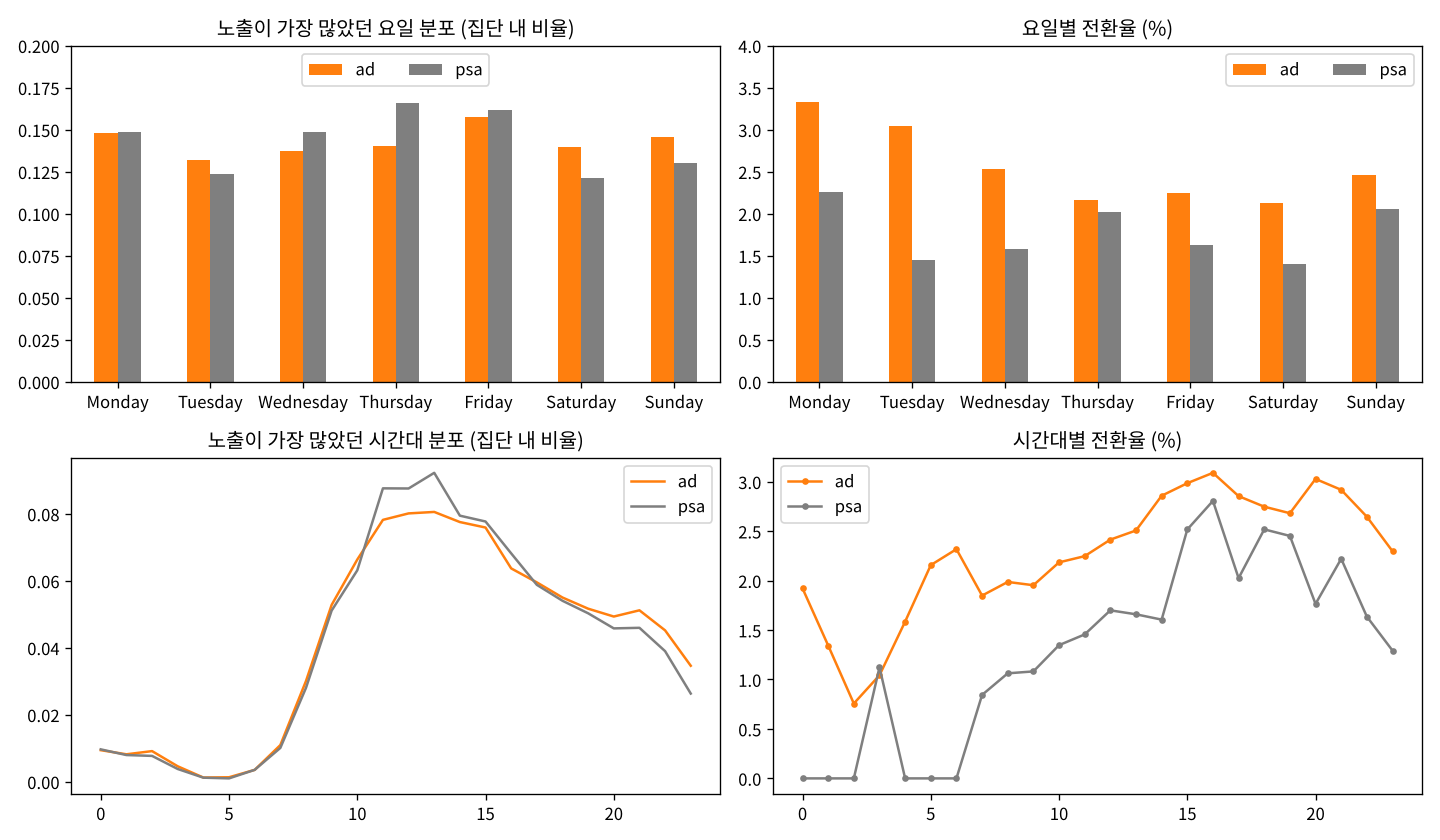

## E7. 검정력과 손익분기 프레임 (5단계 A·D 및 6단계 준비)

### 7-1. 검정력: 이 실험은 효과를 잡을 힘이 있었나

홀드아웃 전환율 1.785%를 기준으로, 현재 표본(홀드아웃 23,524명, 배정비 24:1)에서 유의수준 5%·검정력 80%로 검출 가능한 최소 효과(MDE)는 약 **0.26%p** (상대적으로 약 +14%)다.

- 배정비가 24:1이라, 노출군을 아무리 늘려도 MDE는 **홀드아웃 크기**에 묶인다. 같은 총인원이라면 50:50이 더 정밀하지만, 광고 매출 손실 때문에 홀드아웃을 작게 둔 설계로 보인다.
- 사후 검정력은 계산하지 않는다(관측 p값을 다시 쓴 것일 뿐). 대신 MDE를 결과 해석의 기준으로 쓴다. Part 2에서 관측된 증분 효과(+0.77%p)는 MDE의 약 3배다.

### 7-2. 손익분기 계산: 예산을 늘려도 되는가

데이터에 **광고비와 매출이 없다.** 그래서 "광고가 이익인가"를 직접 계산할 수는 없고, 대신 **"구매 1건이 회사에 남기는 이익(공헌이익)이 얼마라면, 광고비를 얼마까지 써도 되는가"** 라는 기준선을 만든다. 아래 계산의 증분 전환율은 Part 2 4단계에서 추정한 값이다.

**① 증분 전환율 (광고가 사용자 1명당 추가로 만든 구매 확률)**

$$\Delta = p_{ad} - p_{psa} = 2.555\% - 1.785\% = 0.769\%p \approx 0.0077 \qquad (\text{95\% CI } 0.0059 \sim 0.0094)$$

**② 증분 구매 1건에 필요한 노출 사용자 수**

$$\frac{1}{\Delta} = \frac{1}{0.0077} \approx 130\text{명} \qquad (\text{CI 기준 약 } 107 \sim 170\text{명})$$

광고를 130명에게 보여줘야 광고 덕분인 구매가 1건 생긴다는 뜻이다.

**③ 노출 사용자 1명당 손익분기 광고비**

사용자 1명에게 광고를 보여줘서 기대할 수 있는 추가 이익은 $\Delta \times$ 공헌이익이다. 1인당 광고비가 이보다 작으면 이익이다.

$$\text{1인당 손익분기 광고비} = \Delta \times \text{공헌이익}$$

같은 조건을 뒤집어 쓰면 $\dfrac{\text{공헌이익}}{\text{1인당 광고비}} \geq \dfrac{1}{\Delta} \approx 130$, 즉 **구매 1건의 공헌이익이 1인당 광고비의 약 130배 이상**이어야 손해가 아니다. 이는 증분 광고수익률 **iROAS (= 증분 이익 ÷ 광고비) ≥ 1** 과 같은 조건이다.

**④ 손익분기 CPM (노출 1,000회당 광고비)**

광고는 보통 CPM으로 구매하므로 1인당 기준을 노출 기준으로 바꾼다. 노출군 1인당 평균 노출은 **24.8회**다.

$$\text{손익분기 CPM} = \frac{\text{1인당 손익분기 광고비}}{24.8} \times 1{,}000$$

**⑤ 계산 예시: 구매 1건 공헌이익이 30,000원일 때**

| 단계 | 점추정 (Δ = 0.0077) | 보수적 기준 (Δ 하한 = 0.0059) |
|---|---|---|
| 1인당 손익분기 광고비 | 30,000 × 0.0077 ≈ **231원** | 30,000 × 0.0059 ≈ **176원** |
| 노출 1회당 손익분기 단가 | 231 ÷ 24.8 ≈ 9.3원 | 176 ÷ 24.8 ≈ 7.1원 |
| **손익분기 CPM** | **약 9,300원** | **약 7,100원** |

**⑥ 판정 규칙**

| 실제 집행 CPM | 판단 |
|---|---|
| 보수적 CPM(약 7,100원) **미만** | ✅ 확대: 효과를 낮게 잡아도 이익 |
| 보수적 CPM ~ 점추정 CPM(약 9,300원) 사이 | ⚠️ 유지: 이익일 가능성이 높지만 불확실, 소규모 증액 테스트 |
| 점추정 CPM **초과** | ⏸ 축소·재협상 검토: 평균적으로 손해 |

공헌이익이 다른 경우(1만·5만·10만 원)의 표는 Part 2 6단계 코드가 같은 공식으로 계산한다.

**⑦ 이 계산이 기대는 가정**

- **공헌이익은 매출이 아니라 매출 − 원가 − 변동비**다. 매출로 계산하면 손익분기를 과대평가한다.
- 증분 효과 0.77%p가 **예산을 늘려도 그대로 유지된다**고 가정한다. 실제로는 광고를 더 많이 노출할수록 한계효과가 줄어드는(수확 체감) 경우가 많아, 확대 시 손익분기는 더 빡빡해진다.
- 실험 기간의 **단기 구매**만 반영한다. 재구매나 브랜드 인지 같은 장기 효과는 빠져 있다.

**→ 본 분석 반영**: 5단계 심화 분석은 C(세그먼트)를 선택. 손익분기는 공헌이익 가정별 민감도 표로 6단계 의사결정에 반영.

## E8. EDA 종합: 점검 결과와 본 분석 반영

아래 표 하나로 EDA에서 확인한 모든 항목과, 그 결과가 Part 2의 어느 단계에 어떻게 쓰이는지를 정리한다.

| 가이드라인 단계 | 점검 항목 | EDA 결과 (근거) | 판정 | Part 2 반영 |
|---|---|---|---|---|
| 1. 데이터 점검 | 기본 구조 | 588,101행 × 6열, 결측 0, 자료형·범위 이상 없음, 사전 특성 변수 없음 (E1) | ✅ | 변환 없이 사용, 사전 공변량 부재는 한계로 |
| 1. 데이터 점검 | 중복·배정 일관성 | 중복 0, 이중 배정 0, 라벨 값 정상 (E2) | ✅ | **제거 0행** (정제 전후 588,101행) |
| 1. 데이터 점검 | SRM | 96.00 : 4.00, 96:4 기준 p ≈ 1.00 / 50:50 기준은 잘못된 기준 (E2) | ✅ ⚠️ | 96:4 기준으로 점검, 의도 비율 미문서화는 한계 |
| 1. 데이터 점검 | 무작위 배정 품질 | 노출 수 SMD 0.001 / 요일·시간 V ≈ 0.02로 미세한 차이 (E4) | ✅ ⚠️ | 요일·시간 통제 회귀로 강건성 확인 |
| 2. 가설 | 사전 확정 | 결과 탐색 전에 $H_0$, $H_1$, α = 0.05, 양측 확정 (E0) | ✅ | 2단계에서 그대로 유지 |
| 3. 검정 선택 | 지표·집단·조건 | 비율 지표, 독립 2집단, 최소 기대빈도 약 594 (E3) | ✅ | 카이제곱 독립성 검정 (= 두 비율 z검정) |
| 4. 결과 보고 | 효과크기 표현 | 기저율 2%대의 희귀 사건 → V가 구조적으로 작음 (E3) | ⚠️ | 증분 %p + Lift 배수 + V + h 함께 보고 |
| 5B·해석 | 분포·이상치 | 노출 수 왜도 7.4, 상위 1% 5,810명은 실제 헤비 유저, 제외해도 +0.79%p (E5) | ✅ | 제거하지 않음 |
| 해석 | 처치 이후 변수 | `total_ads`, 노출 요일·시간은 실험 중 정해진 값 (E1, E5) | ⚠️ | 통제변수·인과 해석에 쓰지 않음, 한계에 명시 |
| 5C. 세그먼트 | 표본 크기 | 새벽 0~7시 홀드아웃 23~237명, 기대 전환 5건 미만 (E6) | ⚠️ | 30명 미만 제외, Bonferroni·BH 보정, 상호작용 검정 |
| 5A. 검정력 | MDE | 약 0.26%p, 홀드아웃 크기가 정밀도를 결정 (E7) | ✅ | 결과 해석 기준, 사후 검정력 미계산 |
| 6. 의사결정 | 손익분기 | 광고비·매출 없음 → 손익분기 프레임 수립: 1인당 Δ × 공헌이익, CPM 환산 (E7) | ⚠️ | 공헌이익 가정별 민감도 표와 판정 규칙으로 권고 |

**정리**: 데이터 품질과 배정에는 결론을 흔들 문제가 없다. 주의할 점은 ① 결과를 크기(%p·배수)로 읽을 것 ② 처치 이후 변수와 작은 세그먼트를 인과·타겟팅 근거로 쓰지 말 것 ③ 수익성은 가정에 기댄다는 것이다. 이 세 가지를 지키며 Part 2에서 가설을 검정한다.

---

# Part 2. 본 분석: 광고 증분 효과 검정 (Conversion Lift Test)

| 항목 | 내용 |
|---|---|
| 데이터 | Kaggle *Marketing A/B Testing* (https://www.kaggle.com/datasets/faviovaz/marketing-ab-testing) |
| 불러오는 곳 | 동일 데이터 공개 미러 (`libuplift` 깃허브 릴리스), SHA-256 체크섬으로 원본과 동일함을 확인 |
| 원본 대비 변경 | 행 번호 컬럼 삭제, 컬럼명 공백 → `_`, `converted` True/False → 1/0 |
| 내려받은 날짜 | 2026-11-06 |
| 설계 | 사용자 단위 무작위 배정 홀드아웃 실험 (노출군 `ad` 96% : 홀드아웃 `psa` 4%) |
| 핵심 지표 | 구매 전환율 (`converted`) |

분석은 과제 가이드라인의 6단계(데이터 점검 → 가설 → 검정 선택 → 결과 보고 → 심화 분석 → 의사결정)를 따른다. 각 단계의 판단 근거는 Part 1 E8 종합 점검표에 정리돼 있으며, 여기서는 그 결정을 코드로 실행하고 결과를 확정한다.

In [1]:
import hashlib, urllib.request, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import confint_proportions_2indep, proportions_ztest
from statsmodels.stats.multitest import multipletests

np.random.seed(42)
ALPHA = 0.05
URL = "https://github.com/jszymon/uplift_sklearn_data/releases/download/marketing_AB/marketing_AB.csv.gz"
SHA256 = "a318767a73785b7e54fbf36cbf3004115f61e943844b7ac8d3753a893e093d9d"

blob = urllib.request.urlopen(URL).read()
assert hashlib.sha256(blob).hexdigest() == SHA256, "체크섬 불일치: 원본과 다른 파일"
raw = pd.read_csv(io.BytesIO(blob), compression="gzip")
raw.head()

,user_id,test_group,converted,total_ads,most_ads_day,most_ads_hour
0,1069124,ad,0,130,Monday,20
1,1119715,ad,0,93,Tuesday,22
2,1144181,ad,0,21,Tuesday,18
3,1435133,ad,0,355,Tuesday,10
4,1015700,ad,0,276,Friday,14


## 1️⃣ 데이터 품질 점검 (Data Quality & Assignment Check)

측정 결과를 해석하기 전에, **데이터가 실험 설계대로 수집됐는지**부터 확인한다. 중복·배정 오류·배정 비율 불일치(SRM)가 있으면 이후의 모든 수치는 신뢰할 수 없다.

| 컬럼 | 정의 |
|---|---|
| `user_id` | 사용자 식별자 |
| `test_group` | `ad` = 상품 광고 노출군(처치), `psa` = 공익광고 홀드아웃(통제) |
| `converted` | 해당 상품 구매 여부 (1/0) — **핵심 지표** |
| `total_ads` | 실험 기간 중 광고 자리 노출 횟수 |
| `most_ads_day`, `most_ads_hour` | 노출이 가장 많았던 요일·시간 |

In [2]:
# 기본 확인
print("행 수:", len(raw), "| 컬럼:", list(raw.columns))
print(raw.dtypes, "\n")
print("결측치:\n", raw.isna().sum(), "\n")
print("test_group 값:", raw.test_group.unique(), "| converted 값:", sorted(raw.converted.unique()))

행 수: 588101 | 컬럼: ['user_id', 'test_group', 'converted', 'total_ads', 'most_ads_day', 'most_ads_hour']
user_id          int64
test_group         str
converted        int64
total_ads        int64
most_ads_day       str
most_ads_hour    int64
dtype: object 

결측치:
 user_id          0
test_group       0
converted        0
total_ads        0
most_ads_day     0
most_ads_hour    0
dtype: int64 

test_group 값: <StringArray>
['ad', 'psa']
Length: 2, dtype: str | converted 값: [np.int64(0), np.int64(1)]


In [3]:
# 중복 및 배정 일관성
print("user_id 중복 행:", raw.user_id.duplicated().sum())
print("완전히 같은 행:", raw.duplicated().sum())
groups_per_user = raw.groupby("user_id").test_group.nunique()
print("노출군과 홀드아웃에 동시 배정된 사용자:", (groups_per_user > 1).sum())

user_id 중복 행: 0
완전히 같은 행: 0


노출군과 홀드아웃에 동시 배정된 사용자: 0


### SRM 점검 (Sample Ratio Mismatch)

이 실험은 **홀드아웃 설계**다. 광고 매출을 최대한 지키기 위해 대부분에게 광고를 보여주고, 소수만 측정용 통제군으로 떼어 둔 구조로 보인다. 따라서 SRM은 50:50이 아니라 **의도한 배정 비율**과 비교해야 한다.

의도 비율은 데이터 설명에 명시돼 있지 않지만, 관측 비율이 96.00 : 4.00으로 정확히 떨어져 **96:4로 추정**한다. SRM 점검에서는 **p값이 커야 정상**이다(의도 비율과 다르다는 증거가 없음).

In [4]:
n_ad, n_psa = (raw.test_group == "ad").sum(), (raw.test_group == "psa").sum()
N = n_ad + n_psa
print(f"노출군 {n_ad:,} ({n_ad/N:.4%}) vs 홀드아웃 {n_psa:,} ({n_psa/N:.4%})")
print("50:50 기준 (잘못된 기준, 참고용):", stats.chisquare([n_ad, n_psa]).pvalue)
print("96:4 기준 (추정한 의도 비율):  ", stats.chisquare([n_ad, n_psa], [N*0.96, N*0.04]))

노출군 564,577 (96.0000%) vs 홀드아웃 23,524 (4.0000%)
50:50 기준 (잘못된 기준, 참고용): 0.0
96:4 기준 (추정한 의도 비율):   Power_divergenceResult(statistic=np.float64(7.084950828432072e-08), pvalue=np.float64(0.9997876225135022))


In [5]:
# 보조 점검: 노출 요일·시간 분포의 집단 간 차이
for col in ["most_ads_day", "most_ads_hour"]:
    tab = pd.crosstab(raw.test_group, raw[col])
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    print(f"{col}: χ²({dof}) = {chi2:.1f}, p = {p:.3f}, Cramér's V = {np.sqrt(chi2/tab.values.sum()/(min(tab.shape)-1)):.3f}")

most_ads_day: χ²(6) = 235.6, p = 0.000, Cramér's V = 0.020


most_ads_hour: χ²(23) = 192.3, p = 0.000, Cramér's V = 0.018


In [6]:
df = raw.copy()
df["treat"] = (df.test_group == "ad").astype(int)
print(f"정제 전 {len(raw):,}행 → 정제 후 {len(df):,}행 (제거 0행)")

정제 전 588,101행 → 정제 후 588,101행 (제거 0행)


**점검 결과 메모**

- 결측·중복·이중 배정이 없어 **제거한 행은 없다** (정제 전후 588,101행).
- 96:4 기준 SRM 신호 없음 (p ≈ 1.0). 단, 의도 비율이 문서로 확인되지 않은 점은 한계로 남긴다.
- 노출 요일·시간 분포는 통계적으로 다르지만 효과크기가 매우 작다(V ≈ 0.02). 표본이 58만 명이라 미세한 차이까지 검출된 것이며, 두 소재(광고·공익광고)의 **송출 스케줄이 약간 달랐던 흔적**으로 본다. 4단계에서 이를 통제한 모형으로 결론의 강건성을 확인한다.

## 2️⃣ 측정 질문과 가설 (사전 확정)

> Part 1 E0에서 결과를 보기 전에 확정한 내용을 그대로 따른다.

- **측정 질문**: 이 광고는 홀드아웃 대비 해당 상품의 구매 전환율을 높이는가? (광고의 **증분 효과**)
- **핵심 지표**: 구매 전환율 `converted`
- $H_0$: 노출군과 홀드아웃의 전환율이 같다. $p_{ad} = p_{psa}$ (광고의 증분 효과 없음)
- $H_1$: 두 전환율이 다르다. $p_{ad} \neq p_{psa}$
- $\alpha = 0.05$, **양측 검정**: 광고가 브랜드 피로나 거부감으로 전환을 오히려 낮출 가능성까지 열어 둔다.

## 3️⃣ 검정 방법 선택

| 판단 기준 | 이 데이터 |
|---|---|
| 지표 유형 | **비율** (구매 여부 0/1) |
| 비교 집단 | **2개**, 서로 다른 사용자로 구성된 **독립** 집단 |
| 정규성·등분산 | 비율 지표라 해당 없음 → 대신 기대빈도 조건 확인 |

In [7]:
tab = pd.crosstab(df.test_group, df.converted)
_, _, _, expected = stats.chi2_contingency(tab)
print(tab, "\n\n최소 기대빈도:", round(expected.min(), 1))

converted        0      1
test_group               
ad          550154  14423
psa          23104    420 

최소 기대빈도: 593.7


**선택: 카이제곱 독립성 검정 (= 두 비율 z검정)**

핵심 지표가 구매했다/안 했다의 비율이고, 노출군과 홀드아웃은 서로 다른 사용자로 이뤄진 독립 집단이므로 2×2 카이제곱 독립성 검정이 적합하다. 2×2 표에서는 두 비율 z검정과 같은 결과를 준다(χ² = z²). 가장 작은 칸의 기대빈도가 약 594로 근사 조건(≥ 5)을 충분히 넘는다. 배정이 96:4로 불균형하지만 두 비율 검정은 각 집단의 표본 크기를 따로 반영하므로 검정 자체에는 문제가 없고, 다만 **추정 정밀도는 작은 쪽인 홀드아웃(23,524명)에 의해 결정된다.**

## 4️⃣ 결과: 점추정 · 95% 신뢰구간 · 효과크기

전환율처럼 기저율이 낮은 지표는 Cramér's V 같은 표준화 효과크기가 구조적으로 작게 나온다. 그래서 마케팅 의사결정에 바로 쓰이는 **절대 차이(%p, = 증분 전환율)** 와 **상대 차이(Lift, 배수)** 를 함께 보고한다.

In [8]:
conv_ad = df.loc[df.treat == 1, "converted"]; conv_psa = df.loc[df.treat == 0, "converted"]
p_ad, p_psa = conv_ad.mean(), conv_psa.mean()
x = np.array([conv_ad.sum(), conv_psa.sum()]); n = np.array([len(conv_ad), len(conv_psa)])

chi2, p_chi, dof, _ = stats.chi2_contingency(tab, correction=False)
z, p_z = proportions_ztest(x, n)
lo, hi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="newcomb", compare="diff")
rlo, rhi = confint_proportions_2indep(x[0], n[0], x[1], n[1], method="log", compare="ratio")
cramer = np.sqrt(chi2 / n.sum())
h = 2*np.arcsin(np.sqrt(p_ad)) - 2*np.arcsin(np.sqrt(p_psa))
inc_conv = (p_ad - p_psa) * n[0]

print(f"전환율  노출군 {p_ad:.3%} ({x[0]:,}/{n[0]:,})  vs  홀드아웃 {p_psa:.3%} ({x[1]:,}/{n[1]:,})")
print(f"① 점추정  증분 전환율 {100*(p_ad-p_psa):+.2f}%p  |  Lift {p_ad/p_psa:.2f}배 ({100*(p_ad/p_psa-1):+.0f}%)")
print(f"② 95% CI  증분 [{100*lo:+.2f}, {100*hi:+.2f}]%p  |  Lift [{rlo:.2f}, {rhi:.2f}]배")
print(f"③ 효과크기  Cramér's V = {cramer:.3f}, Cohen's h = {h:.3f}")
print(f"χ²({dof}) = {chi2:.1f}, p = {p_chi:.2e}  (z = {z:.2f}, z² = {z**2:.1f})")
print(f"증분 구매 수 (노출군 기준): 약 {inc_conv:,.0f}건 [{lo*n[0]:,.0f} ~ {hi*n[0]:,.0f}]")

전환율  노출군 2.555% (14,423/564,577)  vs  홀드아웃 1.785% (420/23,524)


① 점추정  증분 전환율 +0.77%p  |  Lift 1.43배 (+43%)
② 95% CI  증분 [+0.59, +0.94]%p  |  Lift [1.30, 1.58]배
③ 효과크기  Cramér's V = 0.010, Cohen's h = 0.053
χ²(1) = 54.3, p = 1.71e-13  (z = 7.37, z² = 54.3)
증분 구매 수 (노출군 기준): 약 4,343건 [3,316 ~ 5,284]


In [9]:
print(f"광고 노출군의 구매 전환율이 홀드아웃보다 높았다 ({p_ad:.2%} vs {p_psa:.2%}).")
print(f"{100*(p_ad-p_psa):+.2f}%p (95% CI [{100*lo:+.2f}, {100*hi:+.2f}]), Lift {p_ad/p_psa:.2f}배, "
      f"χ²(1) = {chi2:.1f}, p < .001, Cramér's V = {cramer:.3f}")

광고 노출군의 구매 전환율이 홀드아웃보다 높았다 (2.55% vs 1.79%).
+0.77%p (95% CI [+0.59, +0.94]), Lift 1.43배, χ²(1) = 54.3, p < .001, Cramér's V = 0.010


In [10]:
# 강건성: 노출 요일·시간을 통제한 로지스틱 회귀
lm = smf.logit("converted ~ treat + C(most_ads_day) + C(most_ads_hour)", data=df).fit(disp=0)
print(f"요일·시간 통제 후 광고 오즈비 = {np.exp(lm.params['treat']):.2f}, "
      f"95% CI [{np.exp(lm.conf_int().loc['treat',0]):.2f}, {np.exp(lm.conf_int().loc['treat',1]):.2f}], p = {lm.pvalues['treat']:.1e}")

요일·시간 통제 후 광고 오즈비 = 1.44, 95% CI [1.31, 1.59], p = 2.4e-13


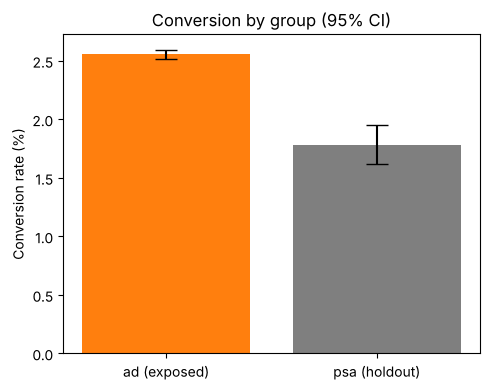

In [11]:
fig, ax = plt.subplots(figsize=(5, 4))
se = np.sqrt(np.array([p_ad, p_psa]) * (1 - np.array([p_ad, p_psa])) / n)
ax.bar(["ad (exposed)", "psa (holdout)"], 100*np.array([p_ad, p_psa]), yerr=196*se, capsize=8, color=["tab:orange", "tab:gray"])
ax.set_ylabel("Conversion rate (%)"); ax.set_title("Conversion by group (95% CI)")
plt.tight_layout(); plt.show()

## 5️⃣ 심화 분석 — C. 세그먼트 분석과 다중비교

캠페인 운영에서는 "언제 광고 효과가 가장 좋은가"를 묻고 싶어진다. 그러나 사후에 세그먼트를 잘게 쪼개 검정을 반복하면 **우연히 유의한 세그먼트가 생길 수밖에 없다.** 노출 요일(7개)과 시간대(24개)로 최대 31번 검정하고(홀드아웃 30명 미만 세그먼트 제외), 보정 전후를 비교한다.

In [12]:
def seg_test(d):
    xa, na = d.loc[d.treat==1, "converted"].sum(), (d.treat==1).sum()
    xp, np_ = d.loc[d.treat==0, "converted"].sum(), (d.treat==0).sum()
    if min(na, np_) < 30 or xp + xa == 0:
        return None
    _, p = proportions_ztest([xa, xp], [na, np_])
    return xa/na - xp/np_, p, np_

rows = []
for col in ["most_ads_day", "most_ads_hour"]:
    for val, d in df.groupby(col):
        r = seg_test(d)
        if r: rows.append([col, val, *r])
seg = pd.DataFrame(rows, columns=["세그먼트", "값", "차이", "p", "홀드아웃 n"])
seg["p_bonf"] = multipletests(seg.p, method="bonferroni")[1]
seg["p_BH"] = multipletests(seg.p, method="fdr_bh")[1]
print(f"세그먼트 검정 {len(seg)}개")
print(f"보정 전 유의: {(seg.p < ALPHA).sum()}개 | Bonferroni 후: {(seg.p_bonf < ALPHA).sum()}개 | BH 후: {(seg.p_BH < ALPHA).sum()}개")
print(f"효과가 전혀 없어도 우연히 유의할 것으로 기대되는 개수: {len(seg)*ALPHA:.1f}개")
print("증분 효과가 음수인 세그먼트:", (seg.차이 < 0).sum(), "/", len(seg))

세그먼트 검정 29개
보정 전 유의: 13개 | Bonferroni 후: 4개 | BH 후: 5개
효과가 전혀 없어도 우연히 유의할 것으로 기대되는 개수: 1.5개
증분 효과가 음수인 세그먼트: 1 / 29


In [13]:
show = seg.assign(차이=lambda d: (100*d.차이).round(2)).sort_values("p")
show[["세그먼트", "값", "차이", "홀드아웃 n", "p", "p_bonf", "p_BH"]].round(4).head(12)

,세그먼트,값,차이,홀드아웃 n,p,p_bonf,p_BH
5,most_ads_day,Tuesday,1.60,2907,0.0000,0.0000,0.0000
6,most_ads_day,Wednesday,0.96,3490,0.0004,0.0109,0.0049
1,most_ads_day,Monday,1.07,3502,0.0005,0.0147,0.0049
19,most_ads_hour,14,1.25,1869,0.0013,0.0384,0.0096
2,most_ads_day,Saturday,0.73,2858,0.0075,0.2170,0.0434
0,most_ads_day,Friday,0.62,3803,0.0116,0.3355,0.0536
18,most_ads_hour,13,0.85,2170,0.0129,0.3750,0.0536
25,most_ads_hour,20,1.26,1077,0.0168,0.4858,0.0546
16,most_ads_hour,11,0.79,2061,0.0170,0.4916,0.0546
15,most_ads_hour,10,0.84,1485,0.0292,0.8475,0.0814


In [14]:
# 세그먼트별 효과 차이를 한 번에 검정: 요일 × 노출 상호작용 (우도비 검정)
m0 = smf.logit("converted ~ treat + C(most_ads_day)", data=df).fit(disp=0)
m1 = smf.logit("converted ~ treat * C(most_ads_day)", data=df).fit(disp=0)
lr = 2 * (m1.llf - m0.llf); ddf = m1.df_model - m0.df_model
print(f"요일 × 노출 상호작용: χ²({ddf:.0f}) = {lr:.1f}, p = {stats.chi2.sf(lr, ddf):.4f}")

요일 × 노출 상호작용: χ²(6) = 16.2, p = 0.0126


**해석**

- 보정 전에는 29개 중 13개가 유의했지만 Bonferroni 후 4개, BH 후 5개만 남는다. 아무 효과가 없어도 약 1.5개는 우연히 유의하게 나오는 구조였다.
- 다만 이 데이터에서는 29개 중 28개 세그먼트가 같은 방향(노출군 > 홀드아웃)이다. 유의 세그먼트가 많은 것은 '만들어진' 결과라기보다 **전체 증분 효과가 실재하기 때문**이고, 유의 여부는 주로 각 세그먼트의 홀드아웃 표본 크기(검정력)에 따라 갈렸다.
- **"월·화요일에 효과가 크니 해당 요일에 예산을 집중하자"는 결론은 내리지 않는다.** 요일 × 노출 상호작용은 경계 수준(p ≈ .013)이고, 요일은 사전에 정한 세그먼트가 아니라 실험 중 노출 행동에서 나온 값이다. 요일 타겟팅은 별도 실험으로 검증할 가설로 넘긴다.

## 6️⃣ 의사결정 (Decision Memo)

In [15]:
print(f"1. 측정 질문: 광고가 홀드아웃 대비 구매 전환율을 높이는가 (양측, α = {ALPHA})")
print(f"2. 데이터 점검: {len(raw):,}행, 중복·이중 배정 0건, 제거 0행. 96:4 기준 SRM 신호 없음")
print(f"3. 검정: 카이제곱 독립성 검정 (= 두 비율 z검정)")
print(f"4. 결과: 증분 {100*(p_ad-p_psa):+.2f}%p [{100*lo:+.2f}, {100*hi:+.2f}], Lift {p_ad/p_psa:.2f}배 [{rlo:.2f}, {rhi:.2f}], "
      f"V = {cramer:.3f}, p = {p_chi:.1e}, 증분 구매 약 {inc_conv:,.0f}건")
print(f"5. 세그먼트 {len(seg)}개 중 보정 전 유의 {(seg.p<ALPHA).sum()}개 → BH 보정 후 {(seg.p_BH<ALPHA).sum()}개")

1. 측정 질문: 광고가 홀드아웃 대비 구매 전환율을 높이는가 (양측, α = 0.05)
2. 데이터 점검: 588,101행, 중복·이중 배정 0건, 제거 0행. 96:4 기준 SRM 신호 없음
3. 검정: 카이제곱 독립성 검정 (= 두 비율 z검정)
4. 결과: 증분 +0.77%p [+0.59, +0.94], Lift 1.43배 [1.30, 1.58], V = 0.010, p = 1.7e-13, 증분 구매 약 4,343건
5. 세그먼트 29개 중 보정 전 유의 13개 → BH 보정 후 5개


### 손익분기 민감도 (Break-even Sensitivity)

Part 1 E7에서 세운 손익분기 프레임(1인당 손익분기 광고비 = 증분 전환율 × 구매 1건 공헌이익, CPM 환산은 1인당 평균 노출 수로 나눔)을 4단계에서 추정한 값으로 계산한다. 공헌이익은 데이터에 없어 1만~10만 원의 가정값을 쓰고, 불확실성을 반영해 **증분 전환율의 95% 신뢰구간 하한으로 계산한 보수적 기준**을 함께 제시한다.

In [16]:
avg_imp = df.loc[df.treat == 1, "total_ads"].mean()
values = [10_000, 30_000, 50_000, 100_000]
be = pd.DataFrame({
    "구매 1건 공헌이익(원)": values,
    "1인당 손익분기 광고비(원)": [v*(p_ad-p_psa) for v in values],
    "보수적 기준: CI 하한(원)": [v*lo for v in values],
    "손익분기 CPM(원)": [v*(p_ad-p_psa)/avg_imp*1000 for v in values],
    "보수적 CPM(원)": [v*lo/avg_imp*1000 for v in values],
}).round(0)
print(f"노출군 1인당 평균 노출 수: {avg_imp:.1f}회 | 증분 전환 1건당 필요 노출군 사용자: {1/(p_ad-p_psa):.0f}명")
be

노출군 1인당 평균 노출 수: 24.8회 | 증분 전환 1건당 필요 노출군 사용자: 130명


,구매 1건 공헌이익(원),1인당 손익분기 광고비(원),보수적 기준: CI 하한(원),손익분기 CPM(원),보수적 CPM(원)
0,10000,77.0,59.0,3099.0,2366.0
1,30000,231.0,176.0,9297.0,7098.0
2,50000,385.0,294.0,15494.0,11830.0
3,100000,769.0,587.0,30989.0,23661.0


### 권고

| 구분 | 권고 | 근거 |
|---|---|---|
| ✅ **Go** | **캠페인 유지** | 증분 전환율 +0.77%p, 신뢰구간 전체가 0보다 큼. 요일·시간 통제, 이상치 제외에도 결론 동일 |
| ⚠️ **Conditional** | **예산 확대는 손익분기 확인 후** | 실제 집행 CPM이 **보수적 CPM 미만이면 확대**, 보수적~점추정 CPM 사이면 유지하며 소규모 증액 테스트, 점추정 CPM 초과면 축소 검토 (판정 규칙: E7) |
| ⏸ **Hold** | **요일·시간 타겟팅 보류** | 사후 탐색으로 발견한 패턴이며, 다중비교 보정 후 근거가 약함 |
| ⏸ **Hold** | **노출 빈도 상향 보류** | 노출 수는 처치 이후 변수로, "많이 보여줄수록 효과적"이라는 인과 근거가 없음 |

**후속 실험 제안**

1. **요일 타겟팅 실험**: "월·화 집중 송출이 균등 송출보다 증분 전환율이 높다"를 사전 가설로 등록하고, 송출 스케줄을 무작위 배정해 검증
2. **빈도(Frequency) 실험**: 노출 상한(frequency cap)을 무작위로 다르게 설정해 최적 노출 횟수를 인과적으로 추정
3. **손익 지표 연동**: 상품 단가·마진과 광고비를 연결해 **iROAS(증분 광고수익률)** 와 **증분 전환 1건당 비용(Cost per Incremental Conversion)** 을 정식 KPI로 관리

### 한계

| 구분 | 내용 |
|---|---|
| 배정 설계 | 96:4 의도 비율은 관측값에서 추정. 실제 의도가 다르면 SRM 판단이 달라짐 |
| 데이터 출처 | 회사·상품·기간·시장 미공개. 일부에서는 교육용 데이터로 보기도 하므로 실제 사업 판단에는 주의 |
| 정밀도 | 홀드아웃이 4%라 추정 정밀도와 세그먼트 분석력이 홀드아웃 크기에 제한됨 |
| 처치 이후 변수 | `total_ads`, 노출 요일·시간은 실험 중 정해진 값이라 인과 해석 불가 |
| 수익성 | 매출·광고비 부재로 iROAS 계산 불가 → 손익분기 민감도로 대체 |
| 장기 효과 | 구매 시점·재구매 정보가 없어 단기 전환 효과만 측정 |

## 부록 A. 용어 정리

| 용어 | 뜻 | 이 보고서에서 |
|---|---|---|
| **증분 효과 (Incrementality)** | 광고가 없었어도 일어났을 전환을 빼고, 광고 때문에 **추가로** 생긴 효과 | 노출군 전환율 − 홀드아웃 전환율 = +0.77%p |
| **홀드아웃 (Holdout)** | 증분 효과를 재기 위해 광고를 일부러 보여주지 않은 무작위 통제군 | 공익광고를 본 4% |
| **PSA (Public Service Announcement)** | 공익광고. 광고 자리·노출은 유지하고 상품 홍보만 빼기 위한 대체 소재 | `test_group = psa` |
| **Lift** | 홀드아웃 대비 상대적 증가율 | +43% (1.43배) |
| **증분 전환 (Incremental Conversions)** | 광고로 새로 생긴 전환 수 | 약 4,300건 |
| **iROAS** | 증분 매출 ÷ 광고비. 1보다 크면 광고비 이상을 벌어들임 | 매출·광고비 부재로 미산출 |
| **CPM** | 노출 1,000회당 광고비 | 손익분기 CPM으로 예산 기준 제시 |
| **SRM** | 실제 배정 비율이 의도 비율과 어긋나는 현상. 배정 오류 신호 | 96:4 기준 이상 없음 |
| **MDE** | 주어진 표본으로 80% 확률로 검출 가능한 최소 효과 | 약 0.26%p |
| **처치 이후 변수** | 실험이 시작된 뒤에 정해진 값. 통제하거나 인과로 해석하면 편향 | `total_ads`, 노출 요일·시간 |

## 부록 B. EDA 그림 재생성 코드

맨 앞 EDA 리포트의 그림 5개를 같은 데이터로 다시 만든다 (`eda_fig1~5.png` 저장).

In [17]:
# EDA 그림 재생성 코드 (데이터를 불러와 eda_fig1~5.png를 만든다)
import io, hashlib, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["font.family"] = ["Noto Sans CJK KR", "AppleGothic", "Malgun Gothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
URL = "https://github.com/jszymon/uplift_sklearn_data/releases/download/marketing_AB/marketing_AB.csv.gz"
blob = urllib.request.urlopen(URL).read()
assert hashlib.sha256(blob).hexdigest().startswith("a318767a")
eda = pd.read_csv(io.BytesIO(blob), compression="gzip")
COL = {"ad": "tab:orange", "psa": "tab:gray"}
G = ["ad", "psa"]
stat = eda.groupby("test_group").converted.agg(["mean", "size", "sum"]).loc[G]

# 그림 1: 집단 구성과 전환율
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(G, stat["size"], color=[COL[g] for g in G])
for i, g in enumerate(G):
    ax[0].text(i, stat["size"][g], f"{stat['size'][g]:,}\n({stat['size'][g]/stat['size'].sum():.0%})", ha="center", va="bottom")
ax[0].set_title("집단 구성 (사용자 수)"); ax[0].set_ylim(0, stat["size"].max() * 1.2)
se = np.sqrt(stat["mean"] * (1 - stat["mean"]) / stat["size"])
ax[1].bar(G, 100 * stat["mean"], yerr=196 * se, capsize=8, color=[COL[g] for g in G])
for i, g in enumerate(G):
    ax[1].text(i, 100 * stat["mean"][g] + 0.15, f"{stat['mean'][g]:.2%}", ha="center")
ax[1].set_title("전환율 (95% 신뢰구간)"); ax[1].set_ylabel("%"); ax[1].set_ylim(0, 3.2)
plt.tight_layout(); plt.savefig("eda_fig1.png", dpi=120); plt.close()

# 그림 2: 전환율 추정치의 확률밀도함수(pdf)와 차이의 pdf
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.linspace(0.012, 0.03, 600)
for g in G:
    m, s = stat["mean"][g], se[g]
    ax[0].plot(100 * x, stats.norm.pdf(x, m, s) / 100, color=COL[g], label=f"{g}: N({m:.3%}, SE {s:.3%})")
    ax[0].fill_between(100 * x, stats.norm.pdf(x, m, s) / 100, alpha=.25, color=COL[g])
ax[0].set_title("집단별 전환율 추정치의 분포 (pdf)"); ax[0].set_xlabel("전환율 (%)"); ax[0].legend(fontsize=8)
d = stat["mean"]["ad"] - stat["mean"]["psa"]; sd = np.sqrt((se ** 2).sum())
pp = stat["sum"].sum() / stat["size"].sum()                       # H0 아래 공통 전환율
sd0 = np.sqrt(pp * (1 - pp) * (1 / stat["size"]["ad"] + 1 / stat["size"]["psa"]))
xd = np.linspace(-5 * sd0, d + 5 * sd, 800)
null_pdf = stats.norm.pdf(xd, 0, sd0) / 100
ax[1].plot(100 * xd, null_pdf, color="gray", ls="--", label=f"H0 아래 차이의 분포 N(0, SE {100*sd0:.3f}%p)")
rej = np.abs(xd) > 1.96 * sd0
ax[1].fill_between(100 * xd, null_pdf, where=rej, color="red", alpha=.35, label="기각역 (양측 α = 0.05)")
est_pdf = stats.norm.pdf(xd, d, sd) / 100
ax[1].plot(100 * xd, est_pdf, color="tab:blue", label="관측 차이의 추정 분포")
lo, hi = d - 1.96 * sd, d + 1.96 * sd
mask = (xd >= lo) & (xd <= hi)
ax[1].fill_between(100 * xd[mask], est_pdf[mask], alpha=.3, color="tab:blue", label=f"95% CI [{100*lo:+.2f}, {100*hi:+.2f}]%p")
ax[1].axvline(100 * d, color="tab:blue", lw=1)
ax[1].text(100 * d, ax[1].get_ylim()[1] * .95, f" 관측 {100*d:+.2f}%p\n (z = {d/sd0:.1f})", fontsize=9, va="top")
ax[1].set_title("귀무가설(H0) 분포 vs 관측 차이 (pdf)"); ax[1].set_xlabel("차이: 광고 − 공익광고 (%p)"); ax[1].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig("eda_fig2.png", dpi=120); plt.close()

# 그림 3: 광고 노출 수의 분포(pdf, 로그 척도)와 노출 수 구간별 전환율
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
grid = np.linspace(0, np.log10(2100), 400)
for g in G:
    v = np.log10(eda.loc[eda.test_group == g, "total_ads"])
    ax[0].plot(grid, stats.gaussian_kde(v, bw_method=.15)(grid), color=COL[g], label=f"{g} (중앙값 {10**np.median(v):.0f}회)")
ax[0].set_xticks([0, 1, 2, 3]); ax[0].set_xticklabels(["1", "10", "100", "1000"])
ax[0].set_title("노출 수 분포 (pdf, 로그 척도, 집단별 정규화)"); ax[0].set_xlabel("total_ads"); ax[0].legend(fontsize=8)
bins = [0, 5, 10, 20, 50, 100, 200, 2100]
labels = ["1-5", "6-10", "11-20", "21-50", "51-100", "101-200", "200+"]
eda["ads_bin"] = pd.cut(eda.total_ads, bins, labels=labels)
cr = eda.groupby(["ads_bin", "test_group"], observed=True).converted.mean().unstack()[G]
for g in G:
    ax[1].plot(labels, 100 * cr[g], marker="o", color=COL[g], label=g)
ax[1].set_title("노출 수 구간별 전환율"); ax[1].set_ylabel("%"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("eda_fig3.png", dpi=120); plt.close()

# 그림 4: 요일·시간대별 노출 분포와 전환율
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
share = pd.crosstab(eda.most_ads_day, eda.test_group, normalize="columns").loc[days, G]
share.plot.bar(ax=ax[0, 0], color=[COL[g] for g in G], rot=0); ax[0, 0].set_title("노출이 가장 많았던 요일 분포 (집단 내 비율)"); ax[0, 0].set_ylim(0, 0.2); ax[0, 0].legend(ncol=2, loc="upper center")
cd = eda.groupby(["most_ads_day", "test_group"]).converted.mean().unstack().loc[days, G] * 100
cd.plot.bar(ax=ax[0, 1], color=[COL[g] for g in G], rot=0); ax[0, 1].set_title("요일별 전환율 (%)"); ax[0, 1].set_ylim(0, 4); ax[0, 1].legend(ncol=2, loc="upper right")
shh = pd.crosstab(eda.most_ads_hour, eda.test_group, normalize="columns")[G]
for g in G: ax[1, 0].plot(shh.index, shh[g], color=COL[g], label=g)
ax[1, 0].set_title("노출이 가장 많았던 시간대 분포 (집단 내 비율)"); ax[1, 0].legend()
ch = eda.groupby(["most_ads_hour", "test_group"]).converted.mean().unstack()[G] * 100
for g in G: ax[1, 1].plot(ch.index, ch[g], color=COL[g], marker=".", label=g)
ax[1, 1].set_title("시간대별 전환율 (%)"); ax[1, 1].legend()
for a in ax.ravel(): a.set_xlabel("")
plt.tight_layout(); plt.savefig("eda_fig4.png", dpi=120); plt.close()

# 그림 5: 세그먼트별 공익광고 표본 크기(검정력)와 노출 수 이상치
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ps = eda[eda.test_group == "psa"].groupby("most_ads_hour").converted.agg(n="size")
base = eda.loc[eda.test_group == "psa", "converted"].mean()
exp_conv = ps["n"] * base
colors = ["tab:red" if e < 5 else "tab:gray" for e in exp_conv]
ax[0].bar(ps.index, ps["n"], color=colors)
for h_, n_, e_ in zip(ps.index, ps["n"], exp_conv):
    if e_ < 5: ax[0].text(h_, n_ + 30, f"{n_}", ha="center", fontsize=7, color="tab:red")
ax[0].set_title("시간대별 공익광고 집단 표본 수 (빨강: 기대 전환 5건 미만)"); ax[0].set_xlabel("most_ads_hour")
p99 = eda.total_ads.quantile(.99)
for g in G:
    v = np.sort(eda.loc[eda.test_group == g, "total_ads"].values)
    ax[1].plot(v, np.arange(1, len(v) + 1) / len(v), color=COL[g], label=g)
ax[1].axvline(p99, ls="--", c="k"); ax[1].text(p99 * 1.1, 0.5, f"상위 1% 경계\n{p99:.0f}회", fontsize=9)
ax[1].set_xscale("log"); ax[1].set_title("노출 수 누적분포 (ECDF, 로그 척도)"); ax[1].set_xlabel("total_ads"); ax[1].legend()
plt.tight_layout(); plt.savefig("eda_fig5.png", dpi=120); plt.close()
print("eda_fig1~5.png 저장 완료")


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'Malgun Gothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'Malgun Gothic' not found.


findfont: Font family 'NanumGothic' not found.


... (11,487 outputs left out)

findfont: Font family 'AppleGothic' not found.


findfont: Font family 'Malgun Gothic' not found.


findfont: Font family 'NanumGothic' not found.


eda_fig1~5.png 저장 완료
